In [1]:
import json, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2

PROJECT = Path.cwd().parent
sys.path.append(str(PROJECT / "src"))
from football_eval import iou

CLIPS = PROJECT / "data" / "clips"
OUT = PROJECT / "outputs" / "05b_camera_tracking"
OUT.mkdir(parents=True, exist_ok=True)
LABELS = sorted(CLIPS.rglob("Labels-GameState.json"))[0]     # SNGS-021, same clip as notebook 04
START = 300                                                  # same START as notebook 04

data = json.loads(LABELS.read_text())
imgs = pd.DataFrame(data["images"])
img_frame = {r["image_id"]: int(Path(r["file_name"]).stem) for _, r in imgs.iterrows()}

rows = []
for a in data["annotations"]:
    if a.get("supercategory") != "object": continue
    bi, bp = a.get("bbox_image"), a.get("bbox_pitch")
    if not bi or not bp: continue
    rows.append(dict(frame=img_frame[a["image_id"]], role=a.get("attributes", {}).get("role"),
                     x=bi["x"], y=bi["y"], w=bi["w"], h=bi["h"],
                     px=bp["x_bottom_middle"], py=bp["y_bottom_middle"]))
gt = pd.DataFrame(rows)
people = gt[gt.role.isin(["player", "goalkeeper", "referee"])].copy()
people["fx"] = people.x + people.w / 2            # feet = bottom-middle of the box
people["fy"] = people.y + people.h
gt_by_frame = {n: g.reset_index(drop=True) for n, g in people.groupby("frame")}

# ground-truth calibration per frame (used for frame 1 as the starting point, and for comparison)
Hs = {}
for fr, g in people.groupby("frame"):
    if len(g) < 6: continue
    H, _ = cv2.findHomography(g[["fx", "fy"]].values.astype(np.float32),
                              g[["px", "py"]].values.astype(np.float32), cv2.RANSAC, 1.5)
    if H is not None: Hs[fr] = H

tr = pd.read_csv(PROJECT / "outputs" / "04_tracking" / "tracks_teams.csv")
print(len(Hs), "frames calibrated from ground truth |", len(tr), "tracked boxes loaded")

750 frames calibrated from ground truth | 1813 tracked boxes loaded


In [2]:
IMG_DIR = next(LABELS.parent.rglob(Path(imgs.file_name.iloc[0]).name)).parent
SCALE = 0.5                                   # match features on half-size images (faster)
S = np.diag([SCALE, SCALE, 1.0]); S_inv = np.linalg.inv(S)
sift = cv2.SIFT_create(nfeatures=2000)
bf = cv2.BFMatcher(cv2.NORM_L2)

def features(n):
    im = cv2.imread(str(IMG_DIR / f"{n:06d}.jpg"))
    gray = cv2.cvtColor(cv2.resize(im, None, fx=SCALE, fy=SCALE), cv2.COLOR_BGR2GRAY)
    kp, des = sift.detectAndCompute(gray, None)
    return np.float32([k.pt for k in kp]), des

def frame_to_prev(prev, cur):
    """3x3 matrix mapping points of the current frame into the previous frame (full-size pixels)."""
    (p0, d0), (p1, d1) = prev, cur
    if d0 is None or d1 is None or len(p0) < 10 or len(p1) < 10: return None, 0
    pairs = [m for m in bf.knnMatch(d1, d0, k=2) if len(m) == 2]
    good = [a for a, b in pairs if a.distance < 0.75 * b.distance]       # keep clearly-best matches
    if len(good) < 12: return None, len(good)
    pc = np.float32([p1[g.queryIdx] for g in good])
    pp = np.float32([p0[g.trainIdx] for g in good])
    G, inl = cv2.findHomography(pc, pp, cv2.RANSAC, 3.0)                 # RANSAC ignores moving players
    if G is None: return None, 0
    return S_inv @ G @ S, int(inl.sum())

In [3]:
N0, N1 = 1, 750
H_cam = {N0: Hs[N0].copy()}       # the ONLY use of labels: calibration of frame 1
inl_log = {}
prev = features(N0); t0 = time.time()
for n in range(N0 + 1, N1 + 1):
    cur = features(n)
    G, ni = frame_to_prev(prev, cur)
    inl_log[n] = ni
    H = H_cam[n - 1] @ G if G is not None else H_cam[n - 1]    # if matching fails, keep the last one
    H_cam[n] = H / H[2, 2]
    prev = cur
    if n % 100 == 0: print(n, f"{time.time() - t0:.0f} s")
print("frames with weak matching (<20 inliers):", sum(v < 20 for v in inl_log.values()))

100 16 s
200 37 s
300 60 s
400 74 s
500 91 s
600 111 s
700 131 s
frames with weak matching (<20 inliers): 0


share of frames with median error < 0.5 m: 24 %
share of frames with median error < 1 m  : 32 %
share of frames with median error < 2 m  : 36 %
frame   1: median error 0.10 m   90th pct 0.23 m
frame  50: median error 0.20 m   90th pct 0.45 m
frame 100: median error 0.34 m   90th pct 0.57 m
frame 200: median error 0.62 m   90th pct 1.53 m
frame 300: median error 3.64 m   90th pct 4.86 m
frame 450: median error 10.86 m   90th pct 12.58 m
frame 600: median error 11.35 m   90th pct 12.52 m
frame 750: median error 12.32 m   90th pct 14.44 m


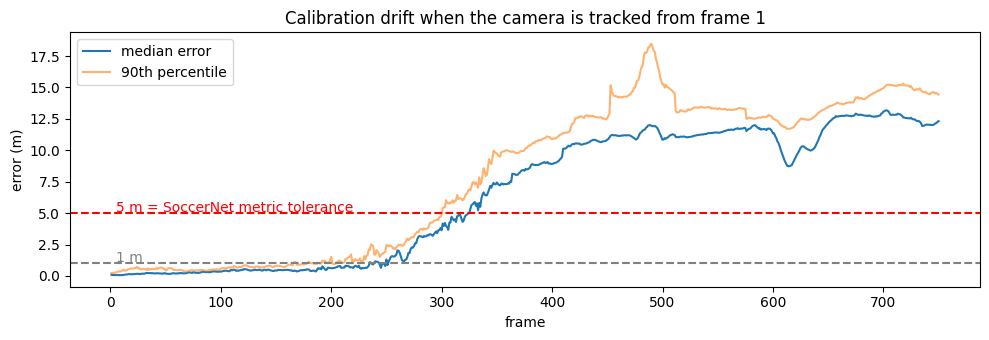

In [4]:
rows = []
for n, g in people.groupby("frame"):
    src = g[["fx", "fy"]].values.astype(np.float32).reshape(-1, 1, 2)
    pr = cv2.perspectiveTransform(src, H_cam[n]).reshape(-1, 2)
    e = np.linalg.norm(pr - g[["px", "py"]].values, axis=1)
    rows.append(dict(frame=n, median_err=np.median(e), p90_err=np.percentile(e, 90)))
drift = pd.DataFrame(rows).set_index("frame")
drift.to_csv(OUT / "camera_tracking_drift.csv")

print("share of frames with median error < 0.5 m:", round((drift.median_err < 0.5).mean() * 100), "%")
print("share of frames with median error < 1 m  :", round((drift.median_err < 1).mean() * 100), "%")
print("share of frames with median error < 2 m  :", round((drift.median_err < 2).mean() * 100), "%")
for f in [1, 50, 100, 200, 300, 450, 600, 750]:
    print(f"frame {f:3d}: median error {drift.loc[f, 'median_err']:.2f} m   90th pct {drift.loc[f, 'p90_err']:.2f} m")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(drift.index, drift.median_err, label="median error")
ax.plot(drift.index, drift.p90_err, alpha=.6, label="90th percentile")
ax.axhline(1, ls="--", c="gray"); ax.axhline(5, ls="--", c="red")
ax.text(5, 1.1, "1 m", color="gray"); ax.text(5, 5.1, "5 m = SoccerNet metric tolerance", color="red")
ax.set_xlabel("frame"); ax.set_ylabel("error (m)")
ax.set_title("Calibration drift when the camera is tracked from frame 1")
ax.legend(); plt.tight_layout(); plt.savefig(OUT / "camera_tracking_drift.png", dpi=130); plt.show()

In [6]:
def eval_tracks(HH):
    errs = []
    for r in tr.itertuples():
        n = START + int(r.frame) + 1
        g = gt_by_frame[n]
        ious = [iou([r.x1, r.y1, r.x2, r.y2], [a.x, a.y, a.x + a.w, a.y + a.h]) for a in g.itertuples()]
        j = int(np.argmax(ious))
        if ious[j] < 0.5: continue
        X, Y = cv2.perspectiveTransform(np.array([[[(r.x1 + r.x2) / 2, r.y2]]], dtype=np.float32), HH[n])[0, 0]
        errs.append(np.hypot(X - g.px[j], Y - g.py[j]))
    e = np.array(errs)
    return dict(matched=len(e), median=round(np.median(e), 2), mean=round(e.mean(), 2), p90=round(np.quantile(e, .9), 2))

print("ground-truth calibration (05)    :", eval_tracks(Hs))
print("camera-tracked calibration (05b) :", eval_tracks(H_cam))

ground-truth calibration (05)    : {'matched': 1616, 'median': np.float64(0.31), 'mean': np.float64(0.43), 'p90': np.float64(0.85)}
camera-tracked calibration (05b) : {'matched': 1616, 'median': np.float64(8.53), 'mean': np.float64(8.25), 'p90': np.float64(11.31)}


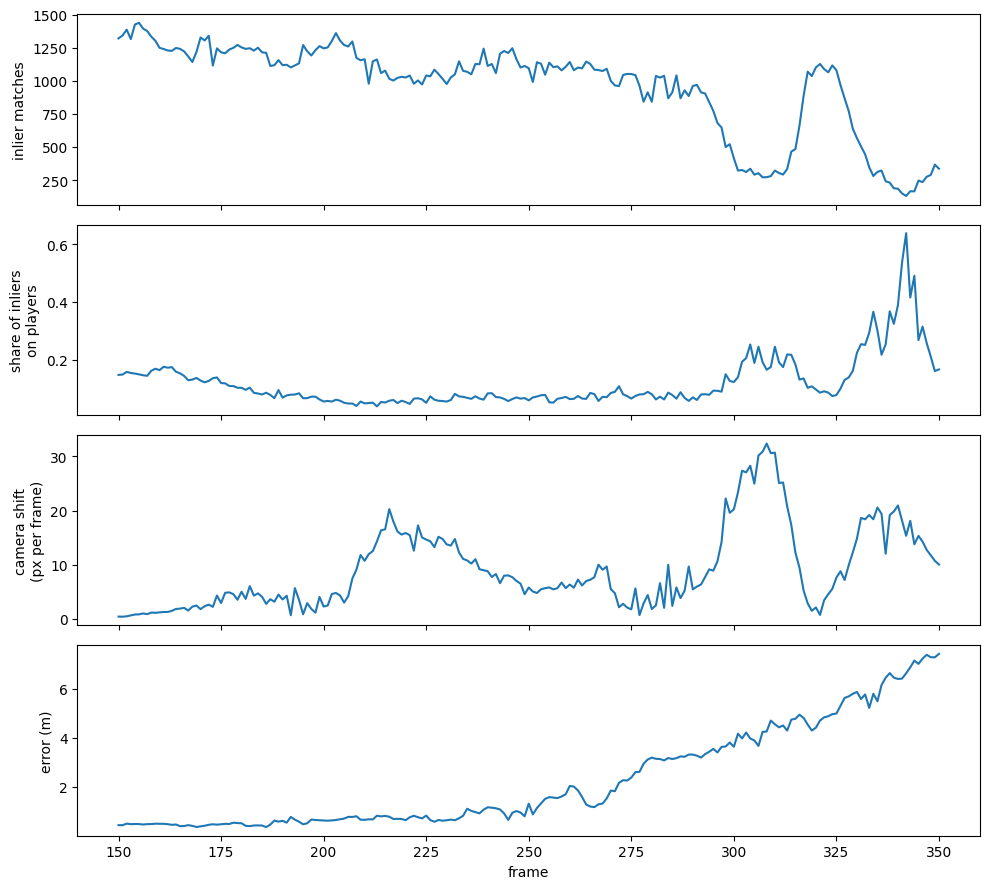

       matches  inliers  on_people  shift_px
count   201.00   201.00     201.00    201.00
mean   1029.50   954.23       0.12      9.08
std     356.79   345.25       0.09      7.37
min     210.00   130.00       0.04      0.39
25%     963.00   868.00       0.07      3.50
50%    1146.00  1075.00       0.08      6.58
75%    1280.00  1205.00       0.15     13.74
max    1493.00  1438.00       0.64     32.37


In [7]:
feat_cache = {}
def feat(n):
    if n not in feat_cache: feat_cache[n] = features(n)
    return feat_cache[n]

def match_pair(n):
    p0, d0 = feat(n - 1); p1, d1 = feat(n)
    pairs = [m for m in bf.knnMatch(d1, d0, k=2) if len(m) == 2]
    good = [a for a, b in pairs if a.distance < 0.75 * b.distance]
    pc = np.float32([p1[g.queryIdx] for g in good]); pp = np.float32([p0[g.trainIdx] for g in good])
    G, inl = cv2.findHomography(pc, pp, cv2.RANSAC, 3.0)
    return pc, pp, (inl.ravel().astype(bool) if inl is not None else np.zeros(len(pc), bool)), G

def share_on_people(n, pts, pad=5):
    inside = np.zeros(len(pts), bool)
    for a in gt_by_frame[n].itertuples():
        x0, y0, x1, y1 = np.array([a.x, a.y, a.x + a.w, a.y + a.h]) * SCALE
        inside |= (pts[:, 0] > x0 - pad) & (pts[:, 0] < x1 + pad) & (pts[:, 1] > y0 - pad) & (pts[:, 1] < y1 + pad)
    return inside.mean() if len(pts) else np.nan

centre = np.array([960.0, 540.0, 1.0]); rows = []
for n in range(150, 351):
    pc, pp, inl, G = match_pair(n)
    if G is None: continue
    c2 = (S_inv @ G @ S) @ centre; c2 = c2[:2] / c2[2]
    rows.append(dict(frame=n, matches=len(pc), inliers=int(inl.sum()),
                     on_people=share_on_people(n, pc[inl]), shift_px=float(np.hypot(*(c2 - centre[:2])))))
diag = pd.DataFrame(rows).set_index("frame")

fig, ax = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
ax[0].plot(diag.inliers); ax[0].set_ylabel("inlier matches")
ax[1].plot(diag.on_people); ax[1].set_ylabel("share of inliers\non players")
ax[2].plot(diag.shift_px); ax[2].set_ylabel("camera shift\n(px per frame)")
ax[3].plot(drift.loc[150:350].median_err); ax[3].set_ylabel("error (m)"); ax[3].set_xlabel("frame")
plt.tight_layout(); plt.savefig(OUT / "drift_diagnosis.png", dpi=130); plt.show()
print(diag.describe().round(2).to_string())

all-features matching done 122 s
grass-only matching done 204 s
                    frames < 1 m (%)  err @200  err @300  err @450  err @750  boxes median err (m)
all features, 3 px              32.0      0.62      3.64     10.86     12.32                  8.53
all features, 1 px              35.0      0.50      1.99      7.25      8.29                  5.00
grass only, 3 px                31.0      0.69      3.36      9.56      9.28                  7.36
grass only, 1 px                35.0      0.31      2.99      2.17      2.05                  2.71


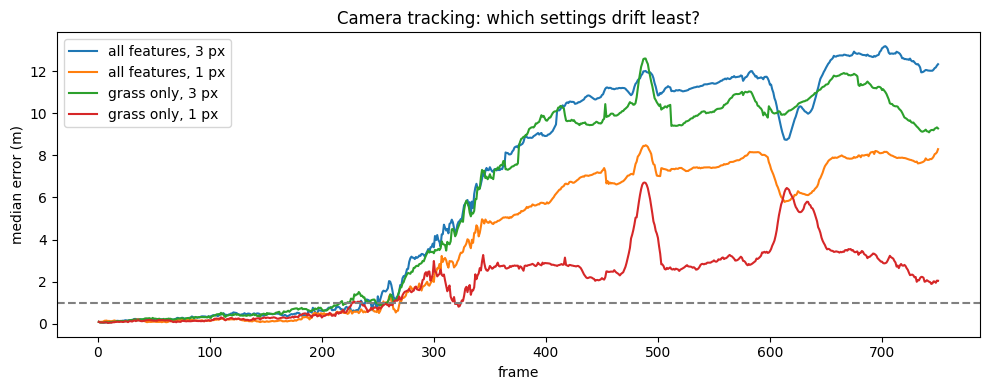

In [8]:
def features(n, use_mask=False):
    im = cv2.resize(cv2.imread(str(IMG_DIR / f"{n:06d}.jpg")), None, fx=SCALE, fy=SCALE)
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    mask = None
    if use_mask:                                  # grass + pitch lines only
        hsv = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
        green = cv2.inRange(hsv, (35, 40, 40), (85, 255, 255))
        mask = cv2.morphologyEx(green, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))   # fills thin lines
    kp, des = sift.detectAndCompute(gray, mask)
    return np.float32([k.pt for k in kp]), des

def ratio_matches(prev, cur):
    (p0, d0), (p1, d1) = prev, cur
    if d0 is None or d1 is None or len(p0) < 10 or len(p1) < 10:
        return np.zeros((0, 2), np.float32), np.zeros((0, 2), np.float32)
    pairs = [m for m in bf.knnMatch(d1, d0, k=2) if len(m) == 2]
    good = [a for a, b in pairs if a.distance < 0.75 * b.distance]
    return (np.float32([p1[g.queryIdx] for g in good]).reshape(-1, 2),
            np.float32([p0[g.trainIdx] for g in good]).reshape(-1, 2))

def build_pairs(use_mask):
    out, prev = {}, features(1, use_mask)
    for n in range(2, 751):
        cur = features(n, use_mask)
        out[n] = ratio_matches(prev, cur)
        prev = cur
    return out

def chain(pairs, thr):
    Hc = {1: Hs[1].copy()}
    for n in range(2, 751):
        pc, pp = pairs[n]
        G = cv2.findHomography(pc, pp, cv2.RANSAC, thr)[0] if len(pc) >= 12 else None
        H = Hc[n - 1] @ (S_inv @ G @ S) if G is not None else Hc[n - 1]
        Hc[n] = H / H[2, 2]
    return Hc

def drift_of(HH):
    out = {}
    for n, g in people.groupby("frame"):
        pr = cv2.perspectiveTransform(g[["fx", "fy"]].values.astype(np.float32).reshape(-1, 1, 2), HH[n]).reshape(-1, 2)
        out[n] = np.median(np.linalg.norm(pr - g[["px", "py"]].values, axis=1))
    return pd.Series(out)

t0 = time.time()
pairs_plain = build_pairs(False); print("all-features matching done", f"{time.time() - t0:.0f} s")
pairs_grass = build_pairs(True);  print("grass-only matching done", f"{time.time() - t0:.0f} s")

variants = {
    "all features, 3 px":  chain(pairs_plain, 3.0),
    "all features, 1 px":  chain(pairs_plain, 1.0),
    "grass only, 3 px":    chain(pairs_grass, 3.0),
    "grass only, 1 px":    chain(pairs_grass, 1.0),
}
curves = {k: drift_of(v) for k, v in variants.items()}

table = pd.DataFrame({
    k: {"frames < 1 m (%)": round((c < 1).mean() * 100),
        "err @200": round(c.loc[200], 2), "err @300": round(c.loc[300], 2),
        "err @450": round(c.loc[450], 2), "err @750": round(c.loc[750], 2),
        "boxes median err (m)": eval_tracks(variants[k])["median"]}
    for k, c in curves.items()}).T
print(table.to_string())
table.to_csv(OUT / "camera_tracking_variants.csv")

fig, ax = plt.subplots(figsize=(10, 4))
for k, c in curves.items(): ax.plot(c.index, c.values, label=k)
ax.axhline(1, ls="--", c="gray"); ax.set_xlabel("frame"); ax.set_ylabel("median error (m)")
ax.set_title("Camera tracking: which settings drift least?"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "camera_tracking_variants.png", dpi=130); plt.show()

In [9]:
sweep = {}
for thr in [0.5, 0.75, 1.0, 1.5]:
    HH = chain(pairs_grass, thr); c = drift_of(HH)
    sweep[f"grass only, {thr} px"] = {"frames < 1 m (%)": round((c < 1).mean() * 100),
                                      "err @300": round(c.loc[300], 2), "err @450": round(c.loc[450], 2),
                                      "err @750": round(c.loc[750], 2),
                                      "boxes median err (m)": eval_tracks(HH)["median"]}
print(pd.DataFrame(sweep).T.to_string())

np.save(OUT / "H_cam_grass_1px.npy", np.stack([variants["grass only, 1 px"][n] for n in range(1, 751)]))

                     frames < 1 m (%)  err @300  err @450  err @750  boxes median err (m)
grass only, 0.5 px               35.0      1.86      2.25      2.66                  2.60
grass only, 0.75 px              37.0      2.12      1.88      1.20                  2.22
grass only, 1.0 px               35.0      2.99      2.17      2.05                  2.71
grass only, 1.5 px               33.0      3.53      2.27      2.06                  3.26


## Findings (SNGS-021, 750 frames; labels used only to calibrate frame 1)
- Idea: calibrate frame 1, then follow the camera with feature matching (SIFT + RANSAC homography between
  consecutive frames) and chain the matrices, so no labels are needed after the first frame.
- First attempt (all features, 3 px RANSAC): good for ~200 frames, then error grew to ~11-12 m
  (8.5 m median on our tracked boxes). Players were NOT the cause (only 5-10% of inliers sat on players
  while the error was rising); the error started with a fast camera pan.
- Matching only on grass and pitch lines (colour mask) and a tighter RANSAC threshold (1 px) cut it
  to a median of 0.3 m at frame 200 and 2-3 m afterwards (2.1 m at frame 750); 35% of frames < 1 m
  (all in the first ~270 frames). Median error on our tracked boxes in the worst stretch (frames 300-449): 2.7 m.
- After the first fast pan the error plateaus instead of growing, which suggests a position-dependent
  model error (e.g. lens distortion, which a homography cannot represent) rather than random drift.
  Not tested.
- Limits: the calibration of frame 1 comes from labels (in practice: a few clicked landmarks or a
  pitch-keypoint model); one clip; a full fix would need lens modelling or per-frame line detection.
- Takeaway: usable for roughly the first 10 s of a clip at < 1 m; beyond that, positions are good to
  about 2-3 m, fine for team shape and formation, not for speed or distance.